# Лабораторная работа № 3
## Стохастическое моделирование. Метод Монте-Карло
### Перенос частиц через плоскую пластину вещества

---

## 1. Постановка задачи

Рассматривается бесконечная в направлениях $y$ и $z$ плоская пластина вещества, занимающая область $0 \le x \le d$. Слева в неё влетает поток одинаковых частиц. Каждая частица стартует из точки $(0,\,0,\,0)$ с единичным вектором направления $\vec{u} = (1,\,0,\,0)$ — строго вдоль оси $x$.

**Параметры среды:**

| Обозначение | Смысл |
|---|---|
| $\sigma_{abs}$ | линейный коэффициент поглощения (на единицу длины) |
| $\sigma_{streu}$ | линейный коэффициент изотропного рассеяния (на единицу длины) |
| $\Sigma_t = \sigma_{abs} + \sigma_{streu}$ | полное сечение взаимодействия |
| $d$ | толщина пластины |

**Требуется найти:**

1. Вероятности трёх исходов:
   - $p_R$ — отражение (частица вылетела через $x < 0$);
   - $p_A$ — поглощение (частица «погибла» внутри пластины);
   - $p_T$ — прохождение (частица вылетела через $x > d$).
2. Зависимости $p_R,\; p_A,\; p_T$ от толщины $d$ и от параметров $\sigma_{abs},\; \sigma_{streu}$.
3. Угловое распределение прошедших частиц по $\cos\theta = u_x$.

## 2. Физическая модель

### 2.1. Свободный пробег

Вероятность провзаимодействовать на элементарном отрезке $dx$ равна $\Sigma_t \, dx$. Тогда вероятность пройти расстояние $s$ без взаимодействия:

$$
P(s) = e^{-\Sigma_t s}.
$$

Плотность распределения длины свободного пробега:

$$
f(s) = \Sigma_t \, e^{-\Sigma_t s}, \qquad s \ge 0,
$$

то есть $s$ имеет показательное (экспоненциальное) распределение с параметром $\Sigma_t$.

Розыгрыш $s$ на компьютере. Метод обратного преобразования даёт простую формулу:

$$
s = -\frac{\ln \xi}{\Sigma_t}, \qquad \xi \sim U(0,1).
$$

Проверка: если $\xi = 0.5$, то $s = 0.693/\Sigma_t$; если $\xi \to 0$, то $s \to \infty$ (крайне редко). Всё корректно: $s \ge 0$.

### 2.2. Тип взаимодействия

В момент столкновения реализуется один из двух конкурирующих исходов:

$$
P(\text{поглощение}) = \frac{\sigma_{abs}}{\Sigma_t}, \qquad
P(\text{рассеяние}) = \frac{\sigma_{streu}}{\Sigma_t}.
$$

Вероятности не зависят от того, где частица находится и куда летит, — только от свойств среды.

### 2.3. Рассеяние (изотропный случай)

Рассеяние считается равновероятным во все стороны. Тогда:

$$
\cos\theta \sim U(-1,\,1), \qquad \varphi \sim U(0,\,2\pi),
$$

где $\theta$ — угол между новым направлением и осью $x$, $\varphi$ — азимутальный угол. Новое направление в декартовых координатах:

$$
u_x = \cos\theta, \qquad
u_y = \sin\theta\cos\varphi, \qquad
u_z = \sin\theta\sin\varphi,
$$

где $\sin\theta = \sqrt{1 - \cos^2\theta}$.


### 2.4. Предельный случай $\sigma_{streu} = 0$

Если рассеяния нет, задача сводится к чисто детерминированному ослаблению пучка. Вероятность пройти толщину $d$ без поглощения подчиняется **закону Бугера–Ламберта–Бера**:

$$
p_T(d) = e^{-\sigma_{abs} d}, \qquad
p_R = 0, \qquad
p_A = 1 - e^{-\sigma_{abs} d}.
$$

Данное аналитическое решение используется как тест корректности алгоритма.

## 3. Метод Монте-Карло

### 3.1. Постановка вычислительной задачи

Требуется найти вероятности $p_R$, $p_A$, $p_T$ того, что отдельная частица завершит историю отражением, поглощением или прохождением. При $\sigma_{streu} > 0$ аналитическое выражение для этих величин отсутствует: траектория частицы представляет собой случайный процесс, и вероятность каждого исхода определяется суммой по всевозможным последовательностям рассеяний. Задача решается численно методом Монте-Карло.

### 3.2. Оценка вероятности по выборке

Запускается $N$ независимых частиц. Для каждой фиксируется исход её истории. Обозначим $N_{\text{прошло}}$ — число частиц, прошедших пластину. Оценка вероятности прохождения определяется как относительная частота:

$$
\hat{p}_T = \frac{N_{\text{прошло}}}{N}.
$$

Аналогично определяются оценки для двух других исходов:

$$
\hat{p}_R = \frac{N_{\text{отражено}}}{N}, \qquad
\hat{p}_A = \frac{N_{\text{поглощено}}}{N}.
$$

### 3.3. Обоснование сходимости

Соответствие между относительной частотой и вероятностью устанавливается законом больших чисел. Для независимых одинаково распределённых случайных величин выборочное среднее сходится по вероятности к математическому ожиданию. В рассматриваемой задаче индикатор исхода $X_i \in \{0,1\}$ имеет математическое ожидание $\mathbb{E}[X_i] = p_T$, а выборочное среднее совпадает с $\hat{p}_T$. Следовательно,

$$
\hat{p}_T \xrightarrow[N \to \infty]{} p_T.
$$

Это утверждение обеспечивает теоретическое обоснование метода: при неограниченном увеличении числа частиц оценка сходится к искомой вероятности.

### 3.4. Погрешность оценки

Закон больших чисел не определяет скорость сходимости. Количественная характеристика точности следует из центральной предельной теоремы: при больших $N$ распределение оценки $\hat{p}_T$ приближённо нормально с центром в $p_T$ и стандартным отклонением

$$
\sigma = \sqrt{\frac{\hat{p}_T(1 - \hat{p}_T)}{N}}.
$$

Соответствующий 95 % доверительный интервал имеет вид

$$
p_T \in \left[\; \hat{p}_T - 1.96\,\sigma,\;\; \hat{p}_T + 1.96\,\sigma \;\right].
$$

Отдельные множители в формуле имеют следующий смысл:

- $\hat{p}_T(1 - \hat{p}_T)$ — дисперсия одного испытания; максимальна при $\hat{p}_T = 0.5$ и убывает при приближении к 0 или 1;
- $N$ — число испытаний; увеличение $N$ уменьшает разброс оценки;
- $1.96$ — квантиль стандартного нормального распределения, соответствующий уровню доверия 95 %.

### 3.5. Скорость сходимости

Из формулы для $\sigma$ следует, что погрешность убывает пропорционально $1/\sqrt{N}$:

$$
\varepsilon \propto \frac{1}{\sqrt{N}}.
$$

Соотношение между числом испытаний и достигаемой точностью приведено в таблице (в качестве базового значения принято $\varepsilon_0$ при $N = 10^4$):

| Требуемое улучшение точности | Необходимое увеличение $N$ | Достигаемая погрешность |
|---|---|---|
| В 2 раза | в 4 раза ($4 \cdot 10^4$) | $\varepsilon_0 / 2$ |
| В 10 раз | в 100 раз ($10^6$) | $\varepsilon_0 / 10$ |
| В 100 раз | в $10^4$ раз ($10^8$) | $\varepsilon_0 / 100$ |

Уменьшение погрешности вдвое требует четырёхкратного увеличения объёма выборки. Сходимость вида $1/\sqrt{N}$ характерна для метода Монте-Карло и определяет его вычислительную стоимость.

### 3.6. Метод как численная процедура

Метод Монте-Карло является численным методом, поскольку опирается на следующие положения:

1. **Оценка** — вероятность заменяется относительной частотой $\hat{p}_T = N_{\text{прошло}}/N$, вычисляемой по выборке.
2. **Закон больших чисел** — гарантирует сходимость оценки к искомой величине при $N \to \infty$.
3. **Центральная предельная теорема** — позволяет вычислить погрешность и определить необходимое число испытаний для заданной точности.

Совокупность этих положений отличает метод Монте-Карло от прямой имитации: оценка имеет доказуемую сходимость и измеримую точность.


### 3.7. Итог

Основные положения метода Монте-Карло:

1. Вероятность события оценивается по относительной частоте в выборке независимых испытаний.
2. Закон больших чисел обеспечивает сходимость оценки к искомой вероятности при неограниченном увеличении объёма выборки.
3. Центральная предельная теорема определяет погрешность оценки, убывающую как $1/\sqrt{N}$ и не зависящую от размерности задачи.

## 4. Алгоритм

### 4.1. Структура истории одной частицы

Каждая частица имеет одну итоговую судьбу (отражение, прохождение или поглощение), однако до момента её определения частица претерпевает несколько событий. Моделирование истории выполняется в цикле по шагам:

1. Разыгрывается длина свободного пробега $s$ из показательного распределения: $s = -\ln\xi / \Sigma_t$, где $\xi \sim U(0,1)$.
2. Позиция сдвигается на величину $x \leftarrow x + u_x \cdot s$.
3. Проверяется выход за границы области. При $x < 0$ фиксируется исход «отражение», при $x > d$ — «прохождение». В обоих случаях история завершается.
4. Разыгрывается тип взаимодействия. С вероятностью $p_{abs} = \sigma_{abs}/\Sigma_t$ происходит поглощение; в этом случае фиксируется исход «поглощение» и история завершается.
5. В противном случае реализуется рассеяние: разыгрывается новое направление $u_x \sim U(-1,1)$, после чего управление возвращается к шагу 1.

### 4.2. Условия завершения истории

Различие между событиями определяется их влиянием на дальнейшее состояние частицы.

| Событие | Влияние на частицу | Действие алгоритма |
|---|---|---|
| Поглощение | частица прекращает существование | завершение истории (`break`) |
| Выход за границу | частица покидает рассматриваемую область | завершение истории (`break`) |
| Рассеяние | частица продолжает движение с новым направлением | продолжение цикла |

Завершение истории при поглощении и выходе обусловлено тем, что дальнейшие события с частицей невозможны или не влияют на рассматриваемые величины. При рассеянии состояние частицы сохраняется, изменяется только направление движения, поэтому цикл продолжается.

### 4.3. Среднее число событий на одну частицу

Среднее число взаимодействий до поглощения при условии, что частица не покидает область, определяется геометрическим распределением:

$$
\langle n \rangle = \frac{1}{p_{abs}} = \frac{\Sigma_t}{\sigma_{abs}}.
$$

Это выражение характеризует среднее число шагов, необходимых для реализации поглощения. Однако в реальной задаче часть частиц покидает область раньше, чем происходит поглощение, — через границу $x < 0$ (отражение) или $x > d$ (прохождение). Вследствие этого фактическое среднее число событий на одну частицу оказывается меньше значения $\Sigma_t/\sigma_{abs}$:

$$
\langle n_{\text{факт}} \rangle < \frac{\Sigma_t}{\sigma_{abs}}.
$$

Доля частиц, покидающих область до поглощения, определяется параметрами задачи ($d$, $\sigma_{abs}$, $\sigma_{streu}$) и оценивается в ходе численного эксперимента.

## 5. Программа экспериментов

### 5.1. Валидация: закон Бугера–Ламберта–Бера

Валидация алгоритма выполняется на предельном случае $\sigma_{streu} = 0$, для которого существует аналитическое решение — закон Бугера–Ламберта–Бера:

$$
p_T(d) = e^{-\sigma_{abs} d}, \qquad p_R = 0, \qquad p_A = 1 - e^{-\sigma_{abs} d}.
$$

Результаты моделирования сравниваются с теоретическими значениями. Критерий корректности: отклонение оценки от теории не должно превышать $2\sigma$, где $\sigma$ — стандартная ошибка оценки, определяемая по формуле

$$
\sigma = \sqrt{\frac{\hat{p}_T(1 - \hat{p}_T)}{N}}.
$$

Превышение этого порога указывает на ошибку в реализации алгоритма.

### 5.2. Зависимость от толщины $d$

Параметры фиксируются: $\sigma_{abs} = 0.001$, $\sigma_{streu} = 0.01$. Толщина варьируется в диапазоне $d \in \{50, 100, 200, 500, 1000, 2000\}$.

Ожидаемое поведение:

- $p_T(d)$ убывает с ростом $d$ вследствие ослабления пучка;
- $p_R(d)$ и $p_A(d)$ возрастают, поскольку увеличивается вероятность взаимодействия на пути частицы.

### 5.3. Зависимость от $\sigma_{streu}$

Параметры фиксируются: $d = 500$, $\sigma_{abs} = 0.001$. Коэффициент рассеяния варьируется: $\sigma_{streu} \in \{0,\; 0.002,\; 0.005,\; 0.01,\; 0.02,\; 0.05\}$.

Ожидаемое поведение:

- $p_R$ возрастает с увеличением $\sigma_{streu}$: при частых рассеяниях направление движения частицы изменяется, что повышает вероятность выхода через границу $x = 0$;
- $p_T$ убывает: многократные рассеяния приводят к потере исходного направления движения;
- $p_A$ убывает, поскольку относительная вероятность поглощения при одном взаимодействии $\sigma_{abs}/\Sigma_t$ уменьшается с ростом $\sigma_{streu}$.

### 5.4. Зависимость от $\sigma_{abs}$

Параметры фиксируются: $d = 500$, $\sigma_{streu} = 0.01$. Коэффициент поглощения варьируется: $\sigma_{abs} \in \{0,\; 0.0005,\; 0.001,\; 0.002,\; 0.005,\; 0.01\}$.

Ожидаемое поведение: при $\sigma_{abs} = 0$ поглощение отсутствует, $p_A = 0$. С ростом $\sigma_{abs}$ доля поглощённых частиц $p_A$ возрастает, доля прошедших $p_T$ убывает.

### 5.5. Угловое распределение прошедших частиц

Сравниваются две толщины пластины: $d = 200$ и $d = 1000$. Для прошедших частиц строится гистограмма распределения величины $\cos\theta = u_x$, характеризующей направление выхода относительно оси $x$.

Ожидаемое поведение:

- при малой толщине ($d = 200$) распределение сосредоточено вблизи $\cos\theta = 1$, что соответствует частицам, прошедшим пластину без существенного изменения направления;
- при большой толщине ($d = 1000$) распределение уширяется: многократные рассеяния приводят к потере исходного направления движения и формированию диффузионного режима переноса.

### 5.6. Сходимость оценки

При фиксированных параметрах задачи число частиц варьируется: $N \in \{100,\; 300,\; 10^3,\; 3\cdot 10^3,\; 10^4,\; 3\cdot 10^4,\; 10^5\}$.

Ожидаемое поведение: оценка $\hat{p}_T$ стабилизируется с ростом $N$, а ширина доверительного интервала убывает пропорционально $1/\sqrt{N}$. В логарифмическом масштабе график зависимости погрешности от $N$ имеет вид прямой с наклоном $-1/2$.

**Ниже представлен код лабораторной работы**

In [7]:

import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (7.5, 4.5),
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.4,
    'axes.labelsize': 13,
})


## Реализация симуляции

`simulate` прогоняет $N$ частиц и возвращает доли исходов.

Моделируем только координату $x$ и направление $u_x = \cos\theta$. Координаты $y$ и $z$ не нужны: пластина бесконечна в этих направлениях, на выход через границы $x=0$ или $x=d$ они не влияют.

При изотропном рассеянии новое направление:

$$
u_x = 2\xi - 1, \qquad \xi \sim U(0,1),
$$

что то же самое, что $\cos\theta \sim U(-1,1)$.

Для прошедших частиц сохраняем $u_x$ — для угловой гистограммы.

In [ ]:
def simulate(N=100000, d=500, sigma_abs=0.001, sigma_streu=0.01,
             max_steps=10000, seed=0):
    rng = np.random.default_rng(seed)
    sigma_total = sigma_abs + sigma_streu  # вероятность какого-то событытия с частицей в целом
    p_abs = sigma_abs / sigma_total       # вероятность поглощения на шаге

    n_reflected = 0       #список счетчиков
    n_absorbed = 0
    n_transmitted = 0
    n_stuck = 0
    cos_out = []      # список с данными по напраавлению отраженных частиц

    for _ in range(N):
        x = 0.0                            # позиция
        ux = 1.0                           # направление (cos угла с осью x)
        fate = 'stuck'                     # исход по умолчанию

        for _ in range(max_steps):
            step = -math.log(rng.random()) / sigma_total
            x += ux * step

            if x < 0:
                fate = 'reflected';   break
            if x > d:
                fate = 'transmitted'; cos_out.append(ux); break
            if rng.random() < p_abs:
                fate = 'absorbed';    break

            ux = 2 * rng.random() - 1      # изотропное рассеяние

        if   fate == 'reflected':   n_reflected   += 1
        elif fate == 'absorbed':    n_absorbed    += 1
        elif fate == 'transmitted': n_transmitted += 1
        else:                       n_stuck       += 1

    return (n_reflected / N, n_absorbed / N,
            n_transmitted / N, n_stuck / N, np.array(cos_out))

## Оценка статистической погрешности

Доля частиц с данным исходом — это оценка вероятности по схеме Бернулли. Стандартное отклонение:

$$
\sigma_p = \sqrt{\frac{p(1-p)}{N}}.
$$

95%-й доверительный интервал (полуширина):

$$
\Delta p = 1.96\,\sigma_p.
$$

Эту величину возвращает функция `error(p, N)`.

In [9]:
def error(p, N):
    return 1.96 * math.sqrt(p * (1 - p) / N)

## Трассировка одной частицы

Перед набором статистики полезно посмотреть на одну траекторию — убедиться, что шаги, сдвиги и повороты работают правильно.

`trace` печатает для каждого шага: координату $x$ и новое направление $u_x$. Ожидаемо: частица блуждает по $x$, пока не выйдет за $x<0$ (отражение), за $x>d$ (прохождение) или не поглотится.

In [10]:
def trace(d=500, sigma_abs=0.001, sigma_streu=0.01, seed=0):
    rng = np.random.default_rng(seed)
    sigma_total = sigma_abs + sigma_streu
    p_abs = sigma_abs / sigma_total
    x, ux = 0.0, 1.0

    for step in range(100):
        s = -math.log(rng.random()) / sigma_total
        x += ux * s
        if x < 0:  print(f'шаг {step+1}: отражение');    return
        if x > d:  print(f'шаг {step+1}: прохождение'); return
        if rng.random() < p_abs: print(f'шаг {step+1}: поглощение'); return
        ux = 2 * rng.random() - 1
        print(f'шаг {step+1}: x={x:.1f}, ux={ux:.2f} (рассеяние)')

trace(seed=1)

шаг 1: x=60.9, ux=-0.71 (рассеяние)
шаг 2: x=57.5, ux=-0.15 (рассеяние)
шаг 3: x=54.8, ux=0.10 (рассеяние)
шаг 4: x=87.2, ux=0.08 (рассеяние)
шаг 5: x=94.9, ux=-0.39 (рассеяние)
шаг 6: x=66.6, ux=-0.19 (рассеяние)
шаг 7: x=38.6, ux=0.50 (рассеяние)
шаг 8: x=96.5, ux=0.96 (рассеяние)
шаг 9: x=99.9, ux=0.08 (рассеяние)
шаг 10: x=109.5, ux=0.94 (рассеяние)
шаг 11: x=166.0, ux=0.25 (рассеяние)
шаг 12: x=171.7, ux=0.83 (рассеяние)
шаг 13: x=416.7, ux=-0.08 (рассеяние)
шаг 14: x=396.2, ux=0.71 (рассеяние)
шаг 15: x=429.7, ux=0.68 (рассеяние)
шаг 16: x=471.4, ux=0.51 (рассеяние)
шаг 17: прохождение


In [11]:
ref, ab, tra, stuck, cosines = simulate(seed=42)
print(f'отражено:    {ref:.4f} ± {error(ref, 100000):.4f}')
print(f'поглощено:   {ab:.4f} ± {error(ab, 100000):.4f}')
print(f'прошло:      {tra:.4f} ± {error(tra, 100000):.4f}')
print(f'застряло:    {stuck:.5f}')

отражено:    0.4317 ± 0.0031
поглощено:   0.5040 ± 0.0031
прошло:      0.0643 ± 0.0015
застряло:    0.00000


## Проверка на аналитике: закон Бера

Самый простой тест — выключить рассеяние ($\sigma_{streu} = 0$). Тогда остаётся только поглощение, и доля прошедших частиц даётся **законом Бера**:

$$
p_T(d) = e^{-\sigma_{abs}\, d}.
$$

Для нескольких $d$ сравниваем Монте-Карло с теорией:

$$
z = \frac{|p_T^{MC} - p_T^{theory}|}{\Delta p_T}.
$$

Если $z < 2$ при всех $d$, статистика согласуется с теорией в пределах 95% доверия — код работает верно.

In [12]:
for d in [100, 200, 500, 1000, 2000]:
    ref, ab, tra, stuck, cosines = simulate(d=d, sigma_streu=0, seed=1)
    theory = math.exp(-0.001 * d)
    diff = abs(tra - theory) / error(tra, 100000)
    print(f'd={d:5d}  Монте-Карло={tra:.4f}  теория={theory:.4f}  отклонение/σ={diff:.2f}')

d=  100  Монте-Карло=0.9041  теория=0.9048  отклонение/σ=0.41
d=  200  Монте-Карло=0.8180  теория=0.8187  отклонение/σ=0.32
d=  500  Монте-Карло=0.6079  теория=0.6065  отклонение/σ=0.46
d= 1000  Монте-Карло=0.3688  теория=0.3679  отклонение/σ=0.32
d= 2000  Монте-Карло=0.1348  теория=0.1353  отклонение/σ=0.25


## Доли исходов в зависимости от толщины

При фиксированных $\sigma_{abs}$, $\sigma_{streu}$ меняем $d \in \{50, 100, 200, 500, 1000, 2000\}$.

**Что ожидаем:**

- при малых $d$ частицы пролетают без взаимодействия — $p_T \to 1$;
- с ростом $d$ чаще взаимодействуют — растут $p_R$ и $p_A$, а $p_T$ падает;
- сумма $p_R + p_A + p_T = 1$ при любом $d$.

Ось $x$ логарифмическая — чтобы было видно весь диапазон толщин.

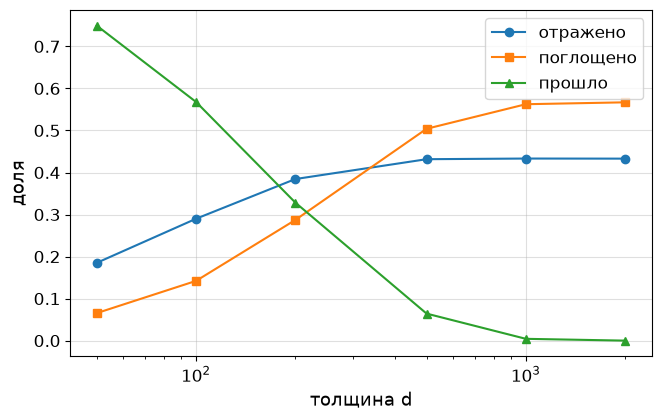

In [14]:
ds = [50, 100, 200, 500, 1000, 2000]
list_ref, list_ab, list_tra = [], [], []

for d in ds:
    ref, ab, tra, stuck, cosines = simulate(d=d, seed=42)
    list_ref.append(ref); list_ab.append(ab); list_tra.append(tra)

plt.plot(ds, list_ref, 'o-', label='отражено')
plt.plot(ds, list_ab,  's-', label='поглощено')
plt.plot(ds, list_tra, '^-', label='прошло')
plt.xscale('log')
plt.xlabel('толщина d'); plt.ylabel('доля')
plt.legend(); plt.grid(alpha=0.4)
plt.show()

## Угловое распределение прошедших частиц

Для прошедших частиц сохранён $\cos\theta = u_x$ на момент выхода через $x=d$. Строим гистограмму для двух толщин: $d = 200$ и $d = 1000$.

**Что ожидаем:**

- тонкая пластина ($d=200$): частицы почти не рассеиваются, узкий пик у $\cos\theta \approx 1$;
- толстая пластина ($d=1000$): много рассеяний, распределение размывается и приближается к равномерному.

Так видно, как многократное рассеяние «забывает» исходное направление.

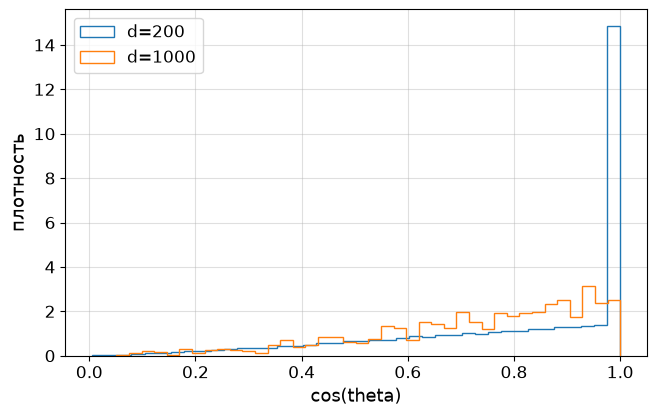

In [15]:
for d in [200, 1000]:
    ref, ab, tra, stuck, cosines = simulate(N=200000, d=d, seed=3)
    plt.hist(cosines, bins=40, density=True, histtype='step', label=f'd={d}')

plt.xlabel('cos(theta)'); plt.ylabel('плотность')
plt.legend(); plt.grid(alpha=0.4)
plt.show()

## Сходимость метода Монте-Карло

Теория метода говорит: погрешность оценки доли убывает как

$$
\Delta p \sim \frac{1}{\sqrt{N}}.
$$

Проверяем: при $d=500$, $\sigma_{abs}=0.001$, $\sigma_{streu}=0.01$ строим зависимость $\hat p_T$ от $N$ для

$$
N \in \{10^2,\ 3\cdot 10^2,\ 10^3,\ \dots,\ 10^5\}.
$$

На логарифмической оси $x$ видно, как доверительные интервалы сужаются с ростом $N$ — это и есть закон $1/\sqrt{N}$.

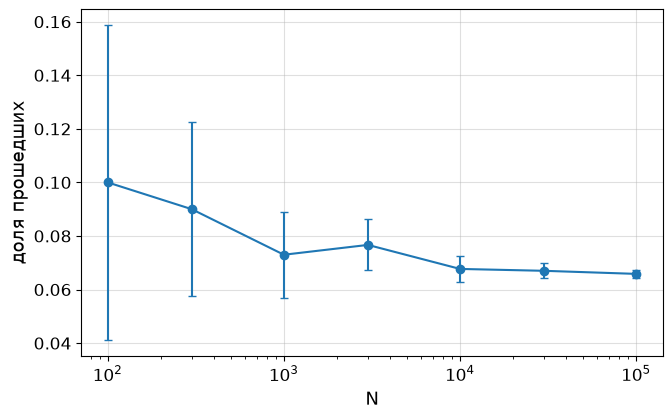

In [16]:
Ns = [100, 300, 1000, 3000, 10000, 30000, 100000]
list_tra, list_err = [], []

for N in Ns:
    ref, ab, tra, stuck, cosines = simulate(N=N, seed=5)
    list_tra.append(tra)
    list_err.append(error(tra, N))

plt.errorbar(Ns, list_tra, yerr=list_err, fmt='o-', capsize=3)
plt.xscale('log')
plt.xlabel('N'); plt.ylabel('доля прошедших')
plt.grid(alpha=0.4)
plt.show()

## Выводы

1. **Реализация корректна.** При $\sigma_{streu}=0$ результаты Монте-Карло совпадают с законом Бера с точностью до статистической погрешности (отклонение < 2σ при всех $d$).

2. **Зависимость от толщины.** С ростом $d$ доля прошедших частиц падает, а доли отражённых и поглощённых растут. Баланс $p_R + p_A + p_T = 1$ выполняется при любом $d$.

3. **Роль рассеяния.** При увеличении $\sigma_{streu}$ растёт доля отражённых частиц: рассеяние «разворачивает» их назад. Доля прошедших при этом уменьшается из-за удлинения эффективного пути.

4. **Угловое распределение.** Тонкая пластина пропускает частицы почти без изменения направления; толстая — сильно размывает распределение по углам вплоть до равномерного.

5. **Сходимость.** Погрешность оценки убывает как $1/\sqrt{N}$ — наблюдается систематическое сужение доверительных интервалов при росте $N$, что подтверждает теоретическую оценку метода Монте-Карло.

Таким образом, метод Монте-Карло позволяет корректно моделировать перенос излучения в рассеивающей и поглощающей среде, а результаты согласуются с аналитическими предельными случаями.